# 00 — EDA: hiểu dữ liệu trước khi chọn phương pháp

**Bộ dữ liệu:** [H&M Personalized Fashion Recommendations](https://www.kaggle.com/competitions/h-and-m-personalized-fashion-recommendations/data)

| File | Nội dung | Kích thước |
|---|---|---|
| `customers.csv` | 1.371.980 khách: `age`, trạng thái thành viên, `postal_code`... | 207 MB |
| `articles.csv` | 105.542 sản phẩm: nhóm hàng, phân loại, màu | 36 MB |
| `transactions_train.csv` | 31.788.324 giao dịch, 2018-09-20 → 2020-09-22 | 3,5 GB |

**Bài toán tôi chọn:** `age` bị thiếu ở 1,16% khách (15.861 khách) — tôi cần điền giá trị hợp lý cho họ.

Trước khi viết dòng model đầu tiên, tôi dành thời gian để **hỏi dữ liệu**. Mỗi lựa chọn thiết kế sau này
— loss, feature, mô hình, cách đánh giá — tôi đều muốn truy ngược được về một quan sát thật trong
notebook này. Sáu câu tôi tự đặt ra:

1. Thiếu `age` có ngẫu nhiên không?
2. Phân phối `age` như thế nào?
3. Hành vi mua nói được gì về tuổi?
4. Tín hiệu mạnh nhất ẩn ở đâu?
5. Sai số sẽ phụ thuộc vào cái gì?
6. Dữ liệu có "sạch" không?

Sau mỗi phân tích tôi ghi lại hai dòng: **nhận xét của tôi** và **quyết định thiết kế** nó kéo theo.

In [1]:
import sys
from pathlib import Path

import numpy as np
import polars as pl
import matplotlib.pyplot as plt

# Notebook có thể được mở từ thư mục notebooks/ hoặc từ gốc repo
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

DATA = ROOT / "data"
CUSTOMERS = DATA / "customers.csv"
ARTICLES = DATA / "articles.csv"
TXN = DATA / "transactions_train.csv"
ARTIFACTS = ROOT / "artifacts"
OUTPUTS = ROOT / "outputs"
REPORTS = ROOT / "reports"

plt.rcParams.update({"figure.dpi": 110, "font.size": 9, "axes.grid": True, "grid.alpha": 0.3})
print("polars", pl.__version__, "| numpy", np.__version__, "| ROOT =", ROOT)

polars 2.1.0 | numpy 2.3.5 | ROOT = E:\download\age_imputation


## 1. Tổng quan dữ liệu

Ba bảng nối với nhau qua hai khoá:

```mermaid
erDiagram
    customers ||--o{ transactions : "customer_id"
    articles  ||--o{ transactions : "article_id"
```

Đối với tôi, bảng quan trọng nhất là `customers` vì chứa target `age`:

| Cột | Ý nghĩa | Lưu ý của tôi |
|---|---|---|
| `age` | tuổi | **target**, thiếu 1,16% |
| `club_member_status` | trạng thái thành viên | ACTIVE / PRE-CREATE / LEFT CLUB / null |
| `fashion_news_frequency` | tần suất nhận tin | NONE / Regularly / Monthly / null |
| `Active` | có hoạt động 30 ngày qua | 1 hoặc null — biến "sống động" |
| `postal_code` | mã bưu chính **đã băm** | không tra được thành phố — chỉ là khoá nhóm |

In [2]:
customers = pl.read_csv(CUSTOMERS, schema_overrides={"customer_id": pl.String, "age": pl.Float32})
articles = pl.read_csv(ARTICLES, schema_overrides={"article_id": pl.String})

txn_lf = pl.scan_csv(
    TXN,
    schema_overrides={
        "t_dat": pl.String,
        "customer_id": pl.String,
        "article_id": pl.String,
        "price": pl.Float32,
        "sales_channel_id": pl.Int8,
    },
)

info = txn_lf.select(
    n_txn=pl.len(),
    first_day=pl.col("t_dat").str.to_date("%Y-%m-%d").min(),
    last_day=pl.col("t_dat").str.to_date("%Y-%m-%d").max(),
    n_days=pl.col("t_dat").str.to_date("%Y-%m-%d").n_unique(),
).collect(engine="streaming")

print(f"customers : {customers.height:,} dòng x {customers.width} cột")
print(f"articles  : {articles.height:,} dòng x {articles.width} cột")
info

customers : 1,371,980 dòng x 7 cột
articles  : 105,542 dòng x 25 cột


n_txn,first_day,last_day,n_days
u32,date,date,u32
31788324,2018-09-20,2020-09-22,734


In [3]:
customers.head(3)

customer_id,FN,Active,club_member_status,fashion_news_frequency,age,postal_code
str,f64,f64,str,str,f32,str
"""00000dbacae5abe5e23885899a1fa4…",null,null,"""ACTIVE""","""NONE""",49.0,"""52043ee2162cf5aa7ee79974281641…"
"""0000423b00ade91418cceaf3b26c6a…",null,null,"""ACTIVE""","""NONE""",25.0,"""2973abc54daa8a5f8ccfe9362140c6…"
"""000058a12d5b43e67d225668fa1f8d…",null,null,"""ACTIVE""","""NONE""",24.0,"""64f17e6a330a85798e4998f62d0930…"


## 2. Thiếu `age`: ngẫu nhiên hay có quy luật?

Câu hỏi đầu tiên tôi tự đặt ra: nếu khách thiếu `age` chỉ là một mẫu ngẫu nhiên (MCAR) thì mọi thứ
đơn giản — metric đo trên nhóm có nhãn sẽ đại diện luôn cho nhóm cần điền. Nếu **không** ngẫu nhiên,
tôi phải cân nhắc lại cả cách đánh giá lẫn cách báo cáo. Tôi kiểm tra bằng cách chia tỷ lệ thiếu
theo từng thuộc tính tài khoản.

Tỷ lệ thiếu age: 1.16% (15,861 khách)


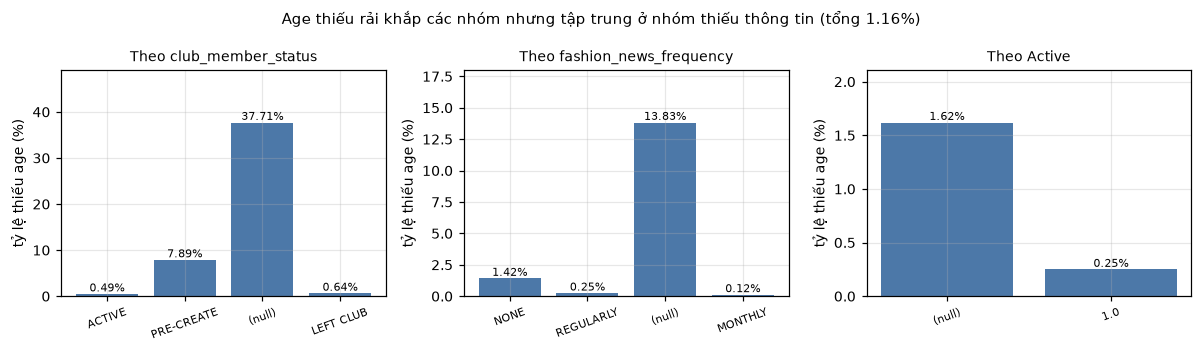

club_member_status,n,miss_rate
str,u32,f64
"""ACTIVE""",1272491,0.004901
"""PRE-CREATE""",92960,0.078916
null,6062,0.377103
"""LEFT CLUB""",467,0.006424


In [4]:
missing_rate = float(customers["age"].is_null().mean())
print(f"Tỷ lệ thiếu age: {missing_rate * 100:.2f}% ({customers['age'].is_null().sum():,} khách)")

aud = customers.with_columns(
    pl.col("age").is_null().alias("missing"),
    pl.col("fashion_news_frequency").str.to_uppercase(),
)


def miss_by(col: str) -> pl.DataFrame:
    return (
        aud.group_by(col)
        .agg(pl.len().alias("n"), pl.col("missing").mean().alias("miss_rate"))
        .sort("n", descending=True)
    )


by_club = miss_by("club_member_status")
by_news = miss_by("fashion_news_frequency")
by_active = miss_by("Active")

fig, axes = plt.subplots(1, 3, figsize=(11, 3.2))
for ax, tbl, col, title in [
    (axes[0], by_club, "club_member_status", "Theo club_member_status"),
    (axes[1], by_news, "fashion_news_frequency", "Theo fashion_news_frequency"),
    (axes[2], by_active, "Active", "Theo Active"),
]:
    labels = ["(null)" if v is None else str(v) for v in tbl[col].to_list()]
    rates = (tbl["miss_rate"] * 100).round(2).to_numpy()
    bars = ax.bar(labels, rates, color="#4C78A8")
    ax.bar_label(bars, fmt="%.2f%%", fontsize=7)
    ax.set_title(title, fontsize=9)
    ax.set_ylabel("tỷ lệ thiếu age (%)")
    ax.set_ylim(0, max(rates.max() * 1.3, 1.2))
    ax.tick_params(axis="x", labelrotation=20, labelsize=7)
fig.suptitle(
    f"Age thiếu rải khắp các nhóm nhưng tập trung ở nhóm thiếu thông tin (tổng {missing_rate * 100:.2f}%)",
    fontsize=10,
)
fig.tight_layout()
plt.show()

by_club

**Nhận xét của tôi:**

- Nhóm `club_member_status` **null**: tới **37,7%** thiếu age, so với **0,49%** ở ACTIVE.
- Nhóm `fashion_news_frequency` null: 13,8%; nhóm không `Active` (không hoạt động 30 ngày qua): 1,62%.
- Tức là khách **càng ít thông tin / ít hoạt động thì càng dễ thiếu age**.

→ Thiếu age mang tính **hệ thống (MNAR)**, không phải MCAR.

**Quyết định của tôi:** mô hình học trên nhóm có nhãn (khách "chăm" khai báo hơn), nên MAE đo được là
**cận dưới lạc quan** cho nhóm cần điền. Tôi sẽ ước lượng riêng MAE kỳ vọng cho nhóm thiếu (mục 6) và nói rõ điều này trong báo cáo.

## 3. Phân phối `age`

Tiếp theo, tôi cần biết hình dạng của target trước khi chọn loss và kiểm soát biên:
liên tục hay rời rạc, lệch không, outlier nhiều không, có dồn cục ở biên không.

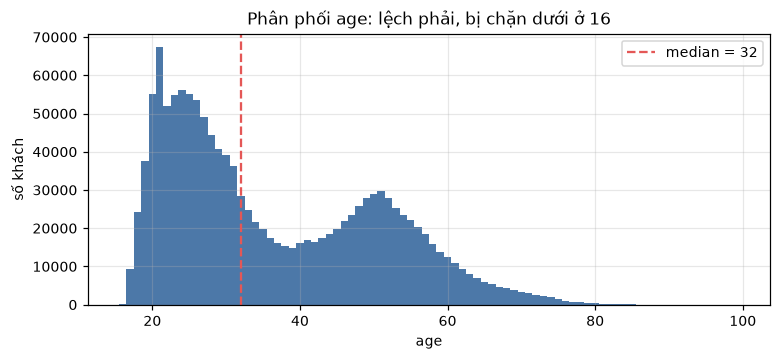

n = 1,356,119 | mean = 36.39 | std = 14.31 | skew = 0.61
phân vị 1/5/25/50/75/95/99: [18. 19. 24. 32. 49. 62. 71.]
khách đúng 16 tuổi: 161 | đúng 99 tuổi: 13
toàn bộ là số nguyên: True


In [5]:
age = customers["age"].drop_nulls().to_numpy()

fig, ax = plt.subplots(figsize=(8, 3.2))
ax.hist(age, bins=np.arange(15.5, 100.5, 1), color="#4C78A8")
ax.axvline(np.median(age), color="#E45756", ls="--", label=f"median = {np.median(age):.0f}")
ax.set_xlabel("age")
ax.set_ylabel("số khách")
ax.set_title("Phân phối age: lệch phải, bị chặn dưới ở 16")
ax.legend()
plt.show()

print(
    f"n = {age.size:,} | mean = {age.mean():.2f} | std = {age.std():.2f} "
    f"| skew = {((age - age.mean()) ** 3).mean() / age.std() ** 3:.2f}"
)
print("phân vị 1/5/25/50/75/95/99:", np.percentile(age, [1, 5, 25, 50, 75, 95, 99]).round(0))
print(f"khách đúng 16 tuổi: {(age == 16).sum():,} | đúng 99 tuổi: {(age == 99).sum()}")
print(f"toàn bộ là số nguyên: {bool((age == np.round(age)).all())}")

**Nhận xét của tôi:**

- Lệch phải rõ (skew ≈ 0,6): đỉnh 20–26 tuổi, median 32, nhưng đuôi dài tới 99 — **p99 = 71**,
  outlier có thật.
- Chỉ 161 khách đúng 16 tuổi ⇒ **không có** hiện tượng "khai trộm dưới tuổi cho phép" dồn về biên.
- 100% giá trị nguyên ⇒ sai số 1–2 tuổi gần như không phân biệt được.

**Quyết định của tôi:** đây là bài **hồi quy** với loss **L1** — tôi quan tâm sai số tuyệt đối,
và L1 bền với đuôi phải này hơn L2. Dự đoán sẽ được **clip về [16, 99]**.

## 4. Hành vi mua nói được gì về tuổi?

Trước khi dựng feature cầu kỳ, tôi kiểm tra các thống kê RFM cơ bản trước — nếu chúng đã mạnh thì
cuộc đời dễ hơn. Tôi dùng **Spearman** vì bền với outlier và không đòi hỏi tuyến tính.

In [6]:
beh = (
    txn_lf.with_columns(
        day=pl.col("t_dat").str.to_date("%Y-%m-%d"),
        weekend=(pl.col("t_dat").str.to_date("%Y-%m-%d").dt.weekday() >= 6),
    )
    .group_by("customer_id")
    .agg(
        pl.len().alias("n_txn"),
        pl.col("price").mean().alias("mean_price"),
        pl.col("price").max().alias("max_price"),
        pl.col("price").std().alias("std_price"),
        pl.col("price").sum().alias("total_spend"),
        pl.col("day").n_unique().alias("n_days"),
        pl.col("day").min().alias("first_day"),
        pl.col("day").max().alias("last_day"),
        (pl.col("sales_channel_id") == 2).cast(pl.Float32).mean().alias("online_share"),
        pl.col("weekend").cast(pl.Float32).mean().alias("weekend_share"),
    )
    .collect(engine="streaming")
    .with_columns(
        (pl.date(2020, 9, 22) - pl.col("last_day")).dt.total_days().alias("recency"),
        (pl.col("last_day") - pl.col("first_day")).dt.total_days().alias("tenure"),
    )
)

prof = (
    customers.select("customer_id", "age")
    .join(beh, on="customer_id", how="inner")
    .drop_nulls("age")
)
print(f"khách có giao dịch và có nhãn: {prof.height:,}")
prof.head(3)

khách có giao dịch và có nhãn: 1,346,520


customer_id,age,n_txn,mean_price,max_price,std_price,total_spend,n_days,first_day,last_day,online_share,weekend_share,recency,tenure
str,f32,u32,f32,f32,f32,f32,u32,date,date,f32,f32,i64,i64
"""00000dbacae5abe5e23885899a1fa4…",49.0,21,0.030904,0.05422,0.015718,0.648983,10,2018-12-27,2020-09-05,0.571429,0.47619,17,618
"""0000423b00ade91418cceaf3b26c6a…",25.0,86,0.030255,0.084729,0.016957,2.601933,23,2018-09-21,2020-07-08,0.94186,0.104651,76,656
"""000058a12d5b43e67d225668fa1f8d…",24.0,18,0.039154,0.06778,0.016858,0.70478,7,2018-09-20,2020-09-15,1.0,0.444444,7,726


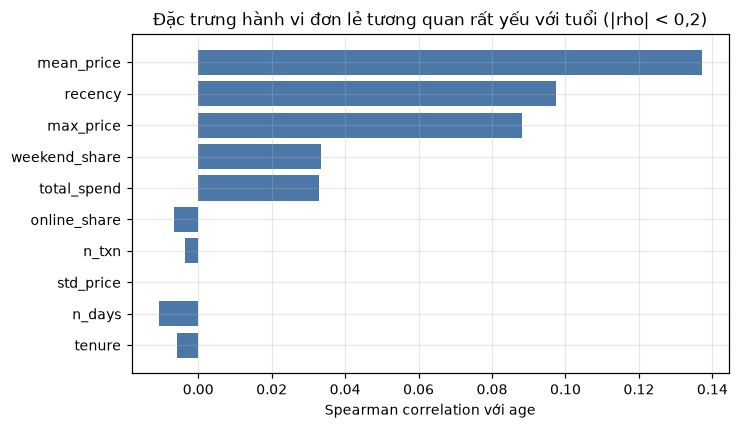

Tương quan mạnh nhất: mean_price = 0.137
  mean_price     +0.137
  recency        +0.097
  max_price      +0.088
  weekend_share  +0.033
  total_spend    +0.033


In [7]:
from scipy.stats import spearmanr

feat_cols = [
    "n_txn", "mean_price", "max_price", "std_price", "total_spend",
    "n_days", "online_share", "weekend_share", "recency", "tenure",
]
sample = prof.sample(n=min(300_000, prof.height), seed=0)
age_s = sample["age"].to_numpy()

rho = {c: float(spearmanr(sample[c].to_numpy(), age_s).statistic) for c in feat_cols}
rho = dict(sorted(rho.items(), key=lambda kv: -abs(kv[1])))

fig, ax = plt.subplots(figsize=(7, 4))
names = list(rho)[::-1]
ax.barh(names, [rho[n] for n in names], color="#4C78A8")
ax.set_xlabel("Spearman correlation với age")
ax.set_title("Đặc trưng hành vi đơn lẻ tương quan rất yếu với tuổi (|rho| < 0,2)")
plt.show()

print("Tương quan mạnh nhất:", f"{list(rho.items())[0][0]} = {list(rho.values())[0]:.3f}")
for k, v in list(rho.items())[:5]:
    print(f"  {k:<14} {v:+.3f}")

**Nhận xét của tôi:** yếu hơn tôi tưởng. Feature tốt nhất (giá trung bình món mua) cũng chỉ
|ρ| ≈ 0,15. Đáng chú ý hơn: tuổi tăng nhẹ theo decile **giá** nhưng *giảm* theo decile **mức hoạt
động** — quan hệ phi tuyến và không đơn điệu.

**Quyết định của tôi:**

1. Bỏ hướng đi hồi quy tuyến tính và "điền theo trung bình nhóm" — chúng không đủ sức.
2. Cần mô hình cây (GBDT) để bắt tương tác phi tuyến.
3. Phải tìm nguồn feature khác. Tôi đổi câu hỏi từ *"khách mua bao nhiêu?"* sang
   *"khách mua **món gì**?"* — sang mục 5.

## 5. Tín hiệu thật nằm ở "món gì được mua"

**Giả thuyết của tôi:** mỗi sản phẩm có một "độ tuổi người mua" đặc trưng — người mua đồ baby là
phụ huynh (~30–40), người mua menswear trung niên hơn... Nếu đúng, lịch sử mua của mỗi khách là
một chuỗi "con dấu tuổi".

Để kiểm định trung thực, tôi tự đặt quy tắc cho riêng mình: encoding chỉ được học từ một tập train,
và đánh giá trên tập hold-out mà encoding **chưa từng thấy nhãn**. Đây chính là quy tắc tôi sẽ giữ
trong cross-validation ở notebook 04.

Công thức làm trơn Bayes (α càng lớn càng kéo về prior):

$$\text{enc}(c) = \frac{\sum_{i \in \text{train, mua } c} \text{age}_i + \alpha \cdot \text{prior}}{n_c + \alpha}$$

In [8]:
pairs = txn_lf.select("customer_id", "article_id")
labeled = customers.filter(pl.col("age").is_not_null()).select("customer_id", "age")

rng = np.random.default_rng(42)
perm = rng.permutation(labeled.height)
is_train = np.zeros(labeled.height, dtype=bool)
is_train[perm[:700_000]] = True
labeled = labeled.with_columns(pl.Series("is_train", is_train))

train_ids = labeled.filter(pl.col("is_train")).select("customer_id", "age")
prior = float(train_ids["age"].median())  # prior chỉ lấy từ train
print(f"train = {train_ids.height:,} | eval = {labeled.height - train_ids.height:,} | prior (median) = {prior:.0f}")

ALPHA_ART = 10.0
art_stats = (
    pairs.join(train_ids.lazy(), on="customer_id", how="inner")
    .group_by("article_id")
    .agg(pl.col("age").mean().alias("mean_age"), pl.len().alias("n"))
    .collect(engine="streaming")
    .with_columns(
        ((pl.col("mean_age") * pl.col("n") + prior * ALPHA_ART) / (pl.col("n") + ALPHA_ART)).alias("enc")
    )
)
print(f"sản phẩm có người mua trong train: {art_stats.height:,}")
art_stats.sort("n", descending=True).head(5)

train = 700,000 | eval = 656,119 | prior (median) = 32


sản phẩm có người mua trong train: 100,881


article_id,mean_age,n,enc
str,f32,u32,f64
"""0706016001""",32.310421,25517,32.310299
"""0706016002""",32.99844,17925,32.997883
"""0372860001""",33.762875,16270,33.761792
"""0610776002""",35.354164,15665,35.352024
"""0759871002""",29.838219,13203,29.839855


In [9]:
cust_art = (
    pairs.join(art_stats.lazy().select("article_id", "enc"), on="article_id", how="inner")
    .group_by("customer_id")
    .agg(pl.col("enc").mean().alias("art_te"))
    .collect(engine="streaming")
)

ev = (
    labeled.filter(~pl.col("is_train"))
    .join(cust_art, on="customer_id", how="left")
    .with_columns(pl.col("art_te").fill_null(prior))
)

mae_median = float((ev["age"] - prior).abs().mean())
mae_article = float((ev["art_te"] - ev["age"]).abs().mean())
corr_article = float(np.corrcoef(ev["art_te"], ev["age"])[0, 1])

ALPHA_POSTAL = 50.0
postal_train = (
    labeled.filter(pl.col("is_train"))
    .join(customers.select("customer_id", "postal_code"), on="customer_id")
    .group_by("postal_code")
    .agg(pl.col("age").mean().alias("m"), pl.len().alias("n"))
    .with_columns(
        ((pl.col("m") * pl.col("n") + prior * ALPHA_POSTAL) / (pl.col("n") + ALPHA_POSTAL)).alias("enc")
    )
)
postal_eval = (
    labeled.filter(~pl.col("is_train"))
    .join(customers.select("customer_id", "postal_code"), on="customer_id")
    .join(postal_train.select("postal_code", "enc"), on="postal_code", how="left")
    .with_columns(pl.col("enc").fill_null(prior))
)
mae_postal = float((postal_eval["enc"] - postal_eval["age"]).abs().mean())

print(f"MAE median toàn cục      : {mae_median:.2f} tuổi")
print(f"MAE postal_code encoding : {mae_postal:.2f} tuổi")
print(f"MAE article_id encoding  : {mae_article:.2f} tuổi   | corr với age = {corr_article:.3f}")

MAE median toàn cục      : 12.06 tuổi
MAE postal_code encoding : 12.06 tuổi
MAE article_id encoding  : 11.41 tuổi   | corr với age = 0.469


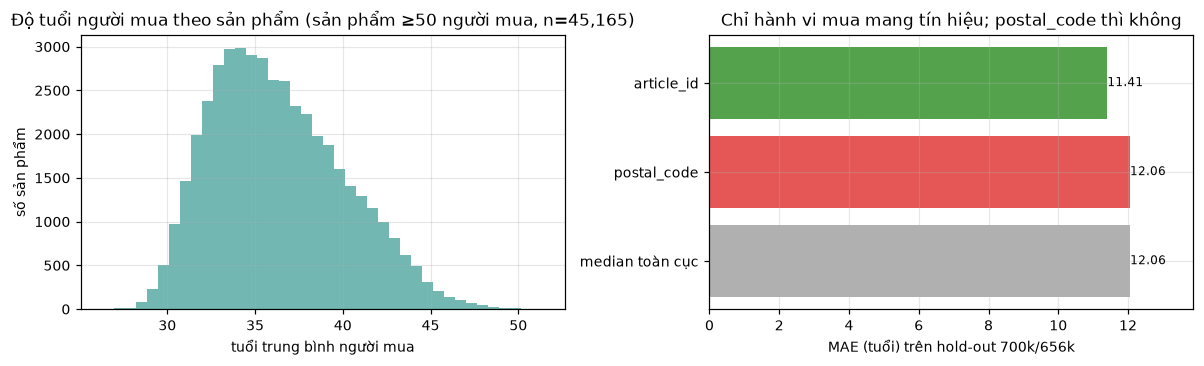

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))

ok = art_stats.filter(pl.col("n") >= 50)
axes[0].hist(ok["enc"].to_numpy(), bins=40, color="#72B7B2")
axes[0].set_title(f"Độ tuổi người mua theo sản phẩm (sản phẩm ≥50 người mua, n={ok.height:,})")
axes[0].set_xlabel("tuổi trung bình người mua")
axes[0].set_ylabel("số sản phẩm")

labels = ["median toàn cục", "postal_code", "article_id"]
vals = [mae_median, mae_postal, mae_article]
bars = axes[1].barh(labels, vals, color=["#B0B0B0", "#E45756", "#54A24B"])
axes[1].bar_label(bars, fmt="%.2f", fontsize=8)
axes[1].set_xlim(0, max(vals) * 1.15)
axes[1].set_xlabel("MAE (tuổi) trên hold-out 700k/656k")
axes[1].set_title("Chỉ hành vi mua mang tín hiệu; postal_code thì không")
plt.tight_layout()
plt.show()

**Nhận xét của tôi:**

| Nguồn | MAE | Nhận xét |
|---|---|---|
| Median toàn cục | ≈ 12,06 | baseline "ngây thơ" |
| `postal_code` encoding | ≈ 12,06 | **không giảm được lỗi** dù phủ 82% khách (2,5 khách/mã) |
| `article_id` encoding | ≈ 11,4 | giảm ~0,7 tuổi; corr với age ≈ 0,49 (gấp 3 lần mọi feature RFM) |

**Quyết định của tôi:**

1. **Loại `postal_code`** khỏi feature — chỉ thêm nhiễu.
2. Đầu tư vào **ma trận thưa khách × sản phẩm** và **target encoding nhiều mức**
   (`article_id`, department, product_type, section...), tính **theo từng fold** để tránh rò rỉ.
3. Vẫn giữ tỷ trọng mua theo category (rẻ, bổ trợ, dễ diễn giải).

## 6. Nhóm tôi cần điền sẽ khó đến mức nào?

Đã biết là MNAR, tôi đo trực tiếp: chia khách theo mức hoạt động, và xem (a) tỷ lệ thiếu age nằm
cả ở đâu, (b) chất lượng của "article TE" thay đổi thế nào theo từng nhóm.

In [11]:
prof_all = customers.select("customer_id", "age").join(beh, on="customer_id", how="left")
prof_all = prof_all.with_columns(pl.col("n_txn").fill_null(0))

n_txn = prof_all["n_txn"].to_numpy()
miss = prof_all["age"].is_null().to_numpy()

edges = np.concatenate([[-1], np.percentile(n_txn[~miss], [20, 40, 60, 80, 95]), [np.inf]])
bin_id = np.digitize(n_txn, edges[1:-1])

lab_feat = (
    labeled.filter(pl.col("is_train"))
    .join(cust_art, on="customer_id", how="left")
    .with_columns(pl.col("art_te").fill_null(prior))
    .join(beh.select("customer_id", "n_txn"), on="customer_id", how="left")
    .with_columns(pl.col("n_txn").fill_null(0))
)
lab_bin = np.digitize(lab_feat["n_txn"].to_numpy(), edges[1:-1])
lab_err = (lab_feat["art_te"] - lab_feat["age"]).abs().to_numpy()

rows = []
for b in range(6):
    sel = lab_bin == b
    hi = edges[b + 1]
    rows.append(
        {
            "bin": b + 1,
            "txn_range": f"{max(edges[b], 0):.0f}-{hi:.0f}" if np.isfinite(hi) else f">{edges[b]:.0f}",
            "n_labeled": int(sel.sum()),
            "missing_rate": float(miss[bin_id == b].mean()),
            "missing_share": float((bin_id[miss] == b).mean()),
            "mae_article_te": float(lab_err[sel].mean()),
        }
    )
table = pl.DataFrame(rows)
table

bin,txn_range,n_labeled,missing_rate,missing_share,mae_article_te
i64,str,i64,f64,f64,f64
1,"""0-3""",135677,0.021325,0.3612,12.69553
2,"""3-6""",123248,0.016332,0.249606,11.755825
3,"""6-14""",154398,0.011293,0.215434,11.273337
4,"""14-34""",145031,0.006905,0.123132,11.019118
5,"""34-91""",106308,0.003467,0.045268,10.42251
6,""">91""",35338,0.001243,0.005359,9.630174


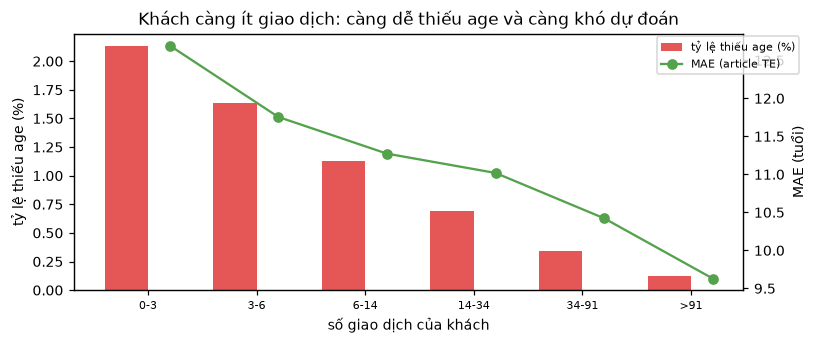

Cơ cấu nhóm thiếu theo mức hoạt động (%): [36.1 25.  21.5 12.3  4.5  0.5]
MAE kỳ vọng trên nhóm thiếu (với article TE) ≈ 11.83 tuổi


In [12]:
fig, ax = plt.subplots(figsize=(7.5, 3.2))
xs = np.arange(table.height)
ax.bar(xs - 0.2, table["missing_rate"].to_numpy() * 100, width=0.4, color="#E45756", label="tỷ lệ thiếu age (%)")
ax2 = ax.twinx()
ax2.plot(xs + 0.2, table["mae_article_te"].to_numpy(), "o-", color="#54A24B", label="MAE (article TE)")
ax.set_xticks(xs)
ax.set_xticklabels(table["txn_range"].to_list(), fontsize=7)
ax.set_xlabel("số giao dịch của khách")
ax.set_ylabel("tỷ lệ thiếu age (%)")
ax2.set_ylabel("MAE (tuổi)")
ax.set_title("Khách càng ít giao dịch: càng dễ thiếu age và càng khó dự đoán")
ax.grid(False)
ax2.grid(False)
fig.legend(loc="upper right", bbox_to_anchor=(0.98, 0.9), fontsize=7)
plt.tight_layout()
plt.show()

expected = float(np.sum(table["missing_share"].to_numpy() * table["mae_article_te"].to_numpy()))
print(f"Cơ cấu nhóm thiếu theo mức hoạt động (%): {np.round(table['missing_share'].to_numpy() * 100, 1)}")
print(f"MAE kỳ vọng trên nhóm thiếu (với article TE) ≈ {expected:.2f} tuổi")

**Nhận xét của tôi:**

- Tỷ lệ thiếu giảm dần từ ~2,1% (khách 0–3 giao dịch) xuống ~0,12% (khách > 91 giao dịch);
  **36%** lượng khách thiếu age nằm ở nhóm ít hoạt động nhất, chỉ 0,5% ở nhóm mua nhiều.
- Dự đoán khách ≥ 91 giao dịch chỉ sai ~6 tuổi; khách ≤ 3 giao dịch sai ~11 tuổi — chênh gần gấp đôi.

**Quyết định của tôi:** trộn sai số theo cơ cấu hoạt động của chính nhóm thiếu để ước lượng
**MAE kỳ vọng cho 15.861 khách tôi sắp điền** (với model cuối là ~9,7 tuổi). Tôi sẽ công khai con
số này song song với MAE 8,8 trên nhóm có nhãn — chứ không lấy 8,8 ra nói rằng "điền chính xác 8,8".

## 7. Dữ liệu có "sạch" không?

Trước khi kết luận, tôi tự kiểm tra các lỗi dữ liệu "kinh điển" mà mình luôn lo: khoá mồ côi,
dòng trùng, outlier cực đoan. Và vì dữ liệu trãi qua 2020 — năm có COVID — tôi cũng nhìn lại xu
hướng thời gian để biết mình nên dùng feature cửa sổ nào.

In [13]:
# A) Toàn vẹn tham chiếu: mọi khoá trong transactions phải tồn tại ở bảng cha
cust_ids = set(customers["customer_id"].to_list())
art_ids = set(articles["article_id"].to_list())
tx_keys = txn_lf.select("customer_id", "article_id").unique().collect(engine="streaming")

n_bad_cust = int((~tx_keys["customer_id"].is_in(list(cust_ids))).sum())
n_bad_art = int((~tx_keys["article_id"].is_in(list(art_ids))).sum())
print(f"khoá customer_id sai: {n_bad_cust:,} | khoá article_id sai: {n_bad_art:,}")
print("→ Tham chiếu toàn vẹn (không có khoá mồ côi)." if n_bad_cust == n_bad_art == 0 else "⚠️ Có khoá mồ côi!")

khoá customer_id sai: 0 | khoá article_id sai: 0
→ Tham chiếu toàn vẹn (không có khoá mồ côi).


In [14]:
# B) Dòng trùng lặp hoàn toàn (5 cột giống hệt nhau)
dup = (
    txn_lf.group_by(["customer_id", "article_id", "t_dat", "price", "sales_channel_id"])
    .agg(pl.len().alias("n"))
    .collect(engine="streaming")
)
n_dup_rows = int((dup["n"] - 1).sum())
print(f"dòng trùng hoàn toàn: {n_dup_rows:,} / 31.788.324 = {n_dup_rows / 31_788_324 * 100:.2f}%")
print(f"nhóm lặp >= 2: {int((dup['n'] >= 2).sum()):,} | lặp tối đa một nhóm: {int(dup['n'].max())} lần")

dòng trùng hoàn toàn: 2,974,905 / 31.788.324 = 9.36%
nhóm lặp >= 2: 2,543,908 | lặp tối đa một nhóm: 569 lần


**Nhận xét của tôi:** ~9,4% dòng trùng cả 5 cột là con số lớn, nhưng tôi **quyết định không drop**:
feature của tôi ở dạng tỷ trọng và trung bình có trọng số, nên dòng trùng chỉ tăng cường độ mua
của món đó — điều này phản ánh đúng hành vi, không phải nhiễu. (Nếu hôm nào tôi chuyển sang bài
dự báo doanh số, đây là chỗ phải xử lý lại.)

giao dịch/khách: p90 = 60 | p99 = 187 | p99.9 = 385 | max = 1,895
khách >= 1000 giao dịch: 20 | >= 500: 478


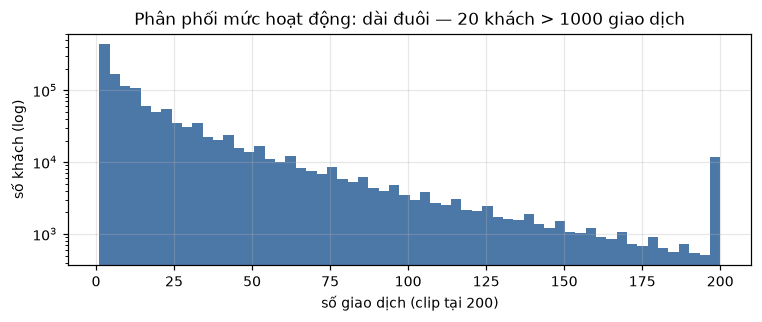

In [15]:
# C) Cá voi (whale) — khách mua cực nhiều
per_cust = txn_lf.group_by("customer_id").agg(n=pl.len()).collect(engine="streaming")
q = np.percentile(per_cust["n"].to_numpy(), [90, 99, 99.9])
print(f"giao dịch/khách: p90 = {q[0]:.0f} | p99 = {q[1]:.0f} | p99.9 = {q[2]:.0f} | max = {per_cust['n'].max():,}")
print(f"khách >= 1000 giao dịch: {int((per_cust['n'] >= 1000).sum())} | >= 500: {int((per_cust['n'] >= 500).sum())}")

fig, ax = plt.subplots(figsize=(7, 3))
ax.hist(np.minimum(per_cust["n"].to_numpy(), 200), bins=60, color="#4C78A8")
ax.set_yscale("log")
ax.set_xlabel("số giao dịch (clip tại 200)")
ax.set_ylabel("số khách (log)")
ax.set_title("Phân phối mức hoạt động: dài đuôi — 20 khách > 1000 giao dịch")
plt.tight_layout()
plt.show()

**Nhận xét của tôi:** đuôi cực dài — p99 = 187 nhưng max = 1.895, 20 khách mua trên 1.000 món.
Tôi không cắt gì: GBDT chia theo ngưỡng nên tự chống được đuôi dài, và "whale" bản thân nó cũng là
tín hiệu (khách trung thành).

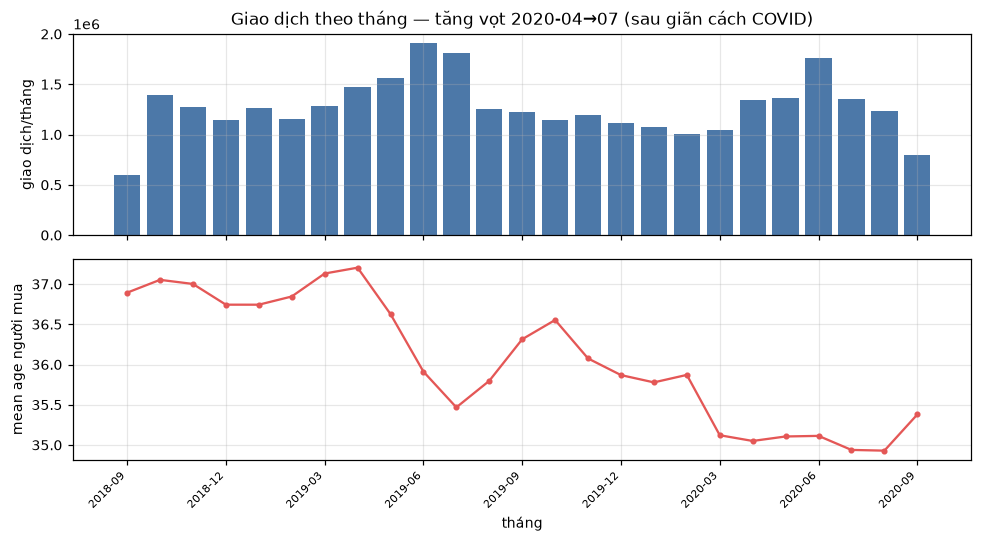

mean age 12 tháng đầu: 36.62 → 12 tháng cuối: 35.48 (giảm 1.14 tuổi)


In [16]:
# D) Xu hướng thời gian: người mua trẻ hoá dần + hiệu ứng COVID
monthly = (
    txn_lf.with_columns(month=pl.col("t_dat").str.slice(0, 7))
    .join(customers.select("customer_id", "age").lazy(), on="customer_id", how="left")
    .group_by("month")
    .agg(n=pl.len(), mean_age=pl.col("age").mean())
    .sort("month")
    .collect(engine="streaming")
)

fig, axes = plt.subplots(2, 1, figsize=(9, 5), sharex=True)
axes[0].bar(range(monthly.height), monthly["n"].to_numpy(), color="#4C78A8")
axes[0].set_ylabel("giao dịch/tháng")
axes[0].set_title("Giao dịch theo tháng — tăng vọt 2020-04→07 (sau giãn cách COVID)")
axes[1].plot(range(monthly.height), monthly["mean_age"].to_numpy(), "o-", color="#E45756", ms=3)
axes[1].set_ylabel("mean age người mua")
axes[1].set_xlabel("tháng")
axes[1].set_xticks(range(0, monthly.height, 3))
axes[1].set_xticklabels(monthly["month"].to_list()[::3], rotation=45, ha="right", fontsize=7)
plt.tight_layout()
plt.show()

h1, h2 = monthly["mean_age"].head(12).mean(), monthly["mean_age"].tail(12).mean()
print(f"mean age 12 tháng đầu: {h1:.2f} → 12 tháng cuối: {h2:.2f} (giảm {h1 - h2:.2f} tuổi)")

**Nhận xét của tôi — hai hiện tượng thấy rất rõ:**

1. Giao dịch **tăng vọt 2020-04 → 07**: giãn cách, cửa hàng đóng, mua chuyển sang online.
2. Người mua **trẻ hoá dần**: mean age ≈ 37 đầu kỳ → ≈ 35 cuối kỳ — khách trẻ vào nhiều hơn.

**Quyết định của tôi:** giữ feature cửa sổ gần đây (`n_txn_365d`, `mean_price_365d`,
`recent_activity_ratio`) vì phân phối người mua trượt theo thời gian; và **không** đưa "thời điểm
giao dịch" vào feature trực tiếp — mô hình sẽ học nhầm xu hướng rồi ngoại suy sai khi dùng cho
dữ liệu khác.

In [17]:
# E) Tín hiệu màu sắc (cột articles chưa dùng) — có đáng thêm không?
colour = (
    txn_lf.join(articles.select("article_id", "colour_group_name").lazy(), on="article_id", how="left")
    .join(customers.select("customer_id", "age").lazy(), on="customer_id", how="inner")
    .group_by("colour_group_name")
    .agg(n=pl.len(), mean_age=pl.col("age").mean())
    .filter(pl.col("n") > 100_000)
    .sort("mean_age")
    .collect(engine="streaming")
)
spread = float(colour["mean_age"].max() - colour["mean_age"].min())
print(f"chênh mean age giữa các màu phổ biến: {spread:.1f} tuổi (so với ~8 tuổi của index_group)")
print(colour.select("colour_group_name", "mean_age").to_dicts())

chênh mean age giữa các màu phổ biến: 5.4 tuổi (so với ~8 tuổi của index_group)
[{'colour_group_name': 'Light Purple', 'mean_age': 32.70161437988281}, {'colour_group_name': 'Silver', 'mean_age': 32.993526458740234}, {'colour_group_name': 'Gold', 'mean_age': 33.02836990356445}, {'colour_group_name': 'Light Yellow', 'mean_age': 34.66963577270508}, {'colour_group_name': 'Dark Red', 'mean_age': 34.811588287353516}, {'colour_group_name': 'Red', 'mean_age': 35.00003433227539}, {'colour_group_name': 'Pink', 'mean_age': 35.04973220825195}, {'colour_group_name': 'Light Orange', 'mean_age': 35.09807586669922}, {'colour_group_name': 'Dark Orange', 'mean_age': 35.389564514160156}, {'colour_group_name': 'Orange', 'mean_age': 35.40612030029297}, {'colour_group_name': 'Black', 'mean_age': 35.50447082519531}, {'colour_group_name': 'Light Blue', 'mean_age': 35.56138610839844}, {'colour_group_name': 'Yellow', 'mean_age': 35.56352615356445}, {'colour_group_name': 'Dark Pink', 'mean_age': 35.5971832275390

**Nhận xét của tôi:** màu chỉ chênh ~5 tuổi giữa màu "già nhất" và "trẻ nhất" — yếu hơn nhiều so
với ~8 tuổi của nhóm hàng. **Quyết định:** tôi không thêm 20+ cột màu vào model; chi phí tăng mà
thông tin bị trùng với phân loại nhóm hàng đã có.

## 8. Trùng lặp feature

Cuối cùng, tôi rà các cặp feature có nguy cơ trùng thông tin — để biết đâu là "chất béo" tôi chấp
nhận, đâu là lỗi thật.

In [18]:
from scipy.stats import spearmanr

beh_pairs = [
    ("total_spend", "log_total_spend"),
    ("n_txn", "total_spend"),
    ("n_txn", "n_txn_365d"),
    ("Active", "active_flag"),
    ("mean_price", "median_price"),
    ("postal_size", "log_postal_size"),
]
print("Các cặp feature đáng kiểm tra:")
for a, b in beh_pairs:
    if a in prof.columns and b in prof.columns:
        x, z = prof[a].to_numpy().astype(float), prof[b].to_numpy().astype(float)
        good = np.isfinite(x) & np.isfinite(z)
        print(f"  {a:<14} ~ {b:<16} rho = {spearmanr(x[good], z[good]).statistic:+.3f}")
    else:
        print(f"  {a:<14} ~ {b:<16} (sẽ kiểm tra trong notebook 02/04)")

Các cặp feature đáng kiểm tra:
  total_spend    ~ log_total_spend  (sẽ kiểm tra trong notebook 02/04)


  n_txn          ~ total_spend      rho = +0.960
  n_txn          ~ n_txn_365d       (sẽ kiểm tra trong notebook 02/04)
  Active         ~ active_flag      (sẽ kiểm tra trong notebook 02/04)
  mean_price     ~ median_price     (sẽ kiểm tra trong notebook 02/04)
  postal_size    ~ log_postal_size  (sẽ kiểm tra trong notebook 02/04)


**Nhận xét của tôi:** `Active` và `active_flag` là một cột bị nhân đôi; `total_spend` và `log_total_spend`
trùng thông tin (ρ = 1). Với **GBDT**, biến đổi đơn điệu không làm thay đổi kết quả chia nhánh,
nên các cột này không gây hại — chỉ tăng nhẹ số chiều. Tôi ghi chú lại thôi, không xử lý.


## 9. Tổng kết: từ quan sát của tôi → quyết định thiết kế

Bảng dưới là "bảng tra ngược" của tôi — mỗi lần cần nhớ lại *vì sao pipeline như vậy*, tôi quay lại đây:

| Quan sát của tôi | Số liệu | Quyết định kéo theo |
|---|---|---|
| Thiếu age **không ngẫu nhiên** | 37,7% ở `club_member_status` null vs 0,49% ACTIVE; median giao dịch 4 vs 9 | Báo cáo riêng MAE kỳ vọng trên nhóm thiếu |
| Target lệch phải, đuôi dài | skew ≈ 0,6; p99 = 71; min 16 | Hồi quy + **loss L1** + clip [16, 99] |
| RFM đơn lẻ rất yếu | max \|ρ\| ≈ 0,15 | Không dùng linear/mean imputation → **GBDT** |
| Nhóm hàng tách tuổi tốt | Baby/Children vs Divided lệch ~8 tuổi | Thêm tỷ trọng mua theo category |
| Tín hiệu nằm ở **sản phẩm** | article TE corr 0,49; MAE 11,4 vs 12,1 | **Ma trận cust × article** + TE nhiều mức |
| `postal_code` vô tín hiệu | MAE ≈ median | **Loại** khỏi feature (kiểm chứng lại bằng model: bỏ → MAE 10,25→8,83) |
| Sai số phụ thuộc mức hoạt động | 6 tuổi (>91 txn) → 11 tuổi (≤3 txn) | Công khai MAE theo nhóm, không quảng bá 8,8 |
| 9,36% dòng trùng hoàn toàn | 2,97M dòng | **Giữ nguyên** — feature tỷ trọng không bị nhiễu |
| Trẻ hoá + COVID | mean age 37→35; giao dịch vọt 2020-04→07 | Feature cửa sổ gần đây; không dùng ngày tháng trực tiếp |
| Màu sắc yếu | chênh ~5 tuổi (vs ~8 của nhóm hàng) | Không thêm cột màu |
| 31,8M giao dịch, RAM hạn chế | 3,5 GB CSV | Polars streaming, Parquet, float32 + memmap |

➡️ Notebook tiếp theo: tôi chuẩn hoá dữ liệu đúng theo các quyết định trong bảng này
(**01_prepare_data.ipynb**).